In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore


In [3]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_I0_h0.jld2", "r") as file:
    spike_array = file["spike_array"][:].T

In [6]:
#Finding first and last spike of each neuron
first_spike = np.zeros(spike_array.shape[0], dtype=int)
last_spike = np.zeros(spike_array.shape[0], dtype=int)

for i in range(spike_array.shape[0]):

    first_spike[i] = next((j for j, x in enumerate(spike_array[i, :]) if x == 1), None)

    for k in range(spike_array[i, :].shape[0] - 1, -1, -1):
        if spike_array[i, k] == 1:
            last_spike[i] = k
            break

print("First spikes:", first_spike)
print("Last spikes:", last_spike)

First spikes: [169414 178094 187260 198152 210889 221360 232451 249881 258477 273789]
Last spikes: [430211 420540 409618 401359 388316 376833 365496 348536 339785 323606]


In [9]:
#Excitatory Input 
amplitude = 0.4
sim_length = 560000
half_triang = sim_length // 2 
flat_line = np.full(20000, -0.1)
up = np.linspace(-0.1, amplitude, num=half_triang + 1)
down = np.linspace(amplitude, -0.1, num=sim_length - half_triang + 1)
exc = np.concatenate([flat_line, up[1:], down[1:], flat_line])

array([-0.1, -0.1, -0.1, ..., -0.1, -0.1, -0.1])

In [25]:
force_first = np.zeros(spike_array.shape[0])
force_last = np.zeros(spike_array.shape[0])

for i in range(spike_array.shape[0]):
    force_first[i]= exc[first_spike[i]]
    force_last[i]= exc[last_spike[i]]

print("First spikes:", force_first)
print("Last spikes:", force_last)

First spikes: [0.1668125  0.1823125  0.19868036 0.21813036 0.240875   0.25957321
 0.27937857 0.31050357 0.32585357 0.35319643]
Last spikes: [0.16747857 0.18474821 0.20425179 0.219      0.24229107 0.26279643
 0.28304107 0.31332679 0.32895357 0.35784464]


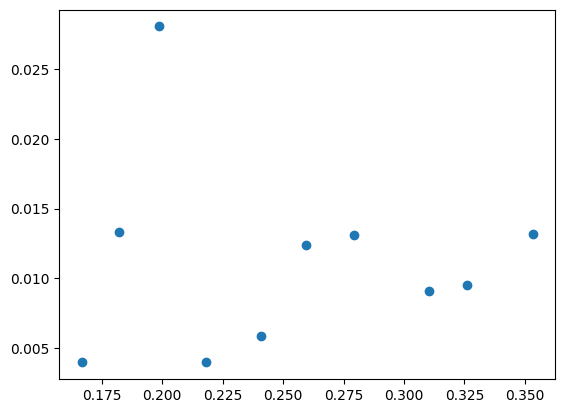

In [30]:
norm_hysteresis=force_last/force_first-1
norm_hysteresis
plt.scatter(force_first,norm_hysteresis)

In [46]:
df = pd.read_csv('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S1.csv')
df = df.dropna(how='all')
plt.scatter(df.iloc[:,0], df.iloc[:,1]/df.iloc[:,0]-1)

xlabel="Force (Recruitment)",xlabel="Force(Derecruitment)/Force(Recruitmemt) - 1",)

SyntaxError: keyword argument repeated: xlabel (3397530872.py, line 3)

In [70]:
df2

,S2,Unnamed: 1
0,1.07410,3.09741
1,1.14456,0.61477
2,1.36251,2.50238
3,1.58482,2.87731
4,1.59224,3.08835
...,...,...
183,64.86946,59.56491
184,69.48783,62.37572
185,73.59973,66.71035
190,NaN,max hyst


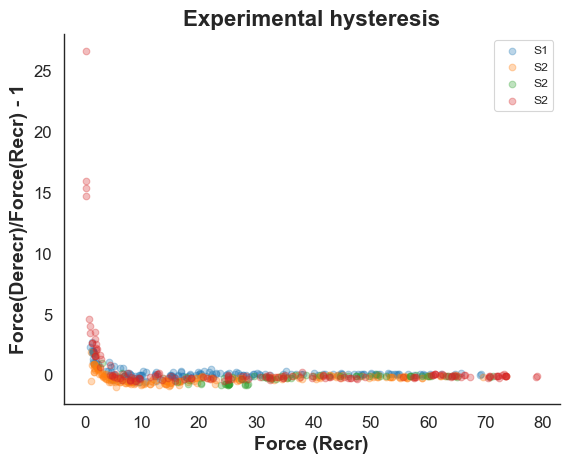

In [76]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

df1 = pd.read_csv('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S1.csv')
df1 = df1.dropna(how='all')

df2 = pd.read_csv('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S2.csv')
df2 = df2.dropna(how='all')

df3 = pd.read_csv('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S3.csv')
df3 = df3.dropna(how='all')

df4 = pd.read_csv('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S4.csv')
df4 = df4.dropna(how='all')

plt.scatter(df1.iloc[:,0], df1.iloc[:,1]/df1.iloc[:,0]-1,alpha=0.3,label='S1')
plt.scatter(df2.iloc[:,0], df2.iloc[:,1]/df2.iloc[:,0]-1,alpha=0.3,label='S2')
plt.scatter(df3.iloc[:,0], df3.iloc[:,1]/df3.iloc[:,0]-1,alpha=0.3,label='S2')
plt.scatter(df4.iloc[:,0], df4.iloc[:,1]/df4.iloc[:,0]-1,alpha=0.3,label='S2')


plt.title('Experimental hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recr)')
plt.ylabel('Force(Derecr)/Force(Recr) - 1')
plt.legend()

sns.despine()

plt.show()

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_69935/2297164936.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = all_dfs.groupby(pd.cut(all_dfs.iloc[:, 0], bins=bin_edges))['hysteresis'].mean()
/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_69935/2297164936.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  variances = all_dfs.groupby(pd.cut(all_dfs.iloc[:, 0], bins=bin_edges))['hysteresis'].var()


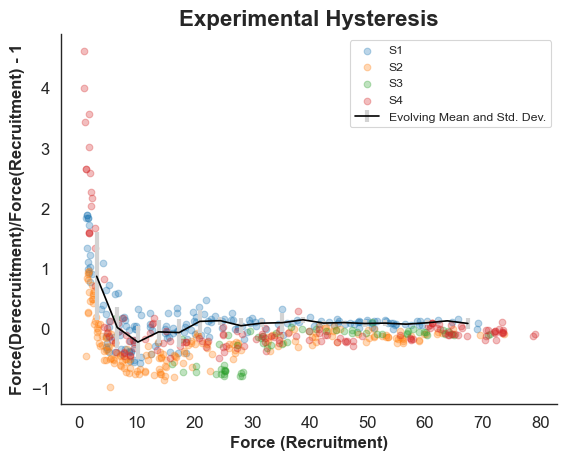

In [86]:

sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3]  # Adjust the threshold as needed

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S1.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S2.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S3.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S4.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S5_.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S6.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S7.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/S8.csv')

all_dfs = pd.concat([df1, df2, df3, df4])

# Define bin edges for the x-axis
bin_edges = np.linspace(all_dfs.iloc[:, 0].min(), all_dfs.iloc[:, 0].max(), num=20) # Adjust the number of bins as needed
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

binned = all_dfs.groupby(pd.cut(all_dfs.iloc[:, 0], bins=bin_edges))
means = binned['hsyteresis'].mean()
std_devs = binned['hysteresis'].std()

# Scatter plots for each DataFrame
plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')


plt.plot(bin_centers, means, '-', color='black', label='Evolving Mean')
plt.fill_between(bin_centers, means - std_devs, means + std_devs, color='gray', alpha=0.5, label='Variance')



plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()

sns.despine()

plt.show()


In [79]:
overall_mean

-0.01311563429421015